# Employee Attrition: What Drives People to Leave?

**Author:** Daljeet Kaur
**Tools:** Python (pandas, NumPy, SciPy, scikit-learn, matplotlib, seaborn)
**Dataset:** [IBM HR Analytics Employee Attrition & Performance](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset): 1,470 employees, 35 attributes. *This is a fictional dataset created by IBM data scientists for HR analytics practice.*

## Business problem
The company loses about 1 in 6 employees, and HR leadership wants to know why. Replacing an employee costs recruiting fees, onboarding time and lost productivity, so even a small cut in attrition is worth real money.

## Objectives
1. Measure overall attrition and where it is concentrated (departments, roles, levels, tenure).
2. Identify the **workplace factors HR can act on** (overtime, travel, pay, stock options, satisfaction) that are most strongly linked to leaving.
3. Build a simple, explainable **risk model** to flag employees for retention conversations.
4. Estimate the **cost of attrition** and what a realistic reduction would save.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, GREY, RED = "#2563eb", "#9ca3af", "#dc2626"
IMG_DIR, RESULTS_DIR = "../images", "../results"

## 1. Load and check the data

In [2]:
hr = pd.read_csv("../data/hr_employee_attrition.csv")
print(hr.shape)
print("Missing values:", int(hr.isna().sum().sum()), "| duplicate employees:", hr.EmployeeNumber.duplicated().sum())
constant = [c for c in hr.columns if hr[c].nunique() == 1]
print("Constant columns dropped:", constant)
hr = hr.drop(columns=constant)
hr["left"] = (hr.Attrition == "Yes").astype(int)
hr.head()

(1470, 35)
Missing values: 0 | duplicate employees: 0
Constant columns dropped: ['EmployeeCount', 'Over18', 'StandardHours']


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,left
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7,0
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0,1
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2,0


The data is clean: no missing values and no duplicates. Three columns hold the same value for everyone (`EmployeeCount`, `Over18`, `StandardHours`), so they carry no information and are dropped.

In [3]:
overall = hr.left.mean()
print(f"Overall attrition: {overall:.1%} ({hr.left.sum()} of {len(hr):,} employees)")

Overall attrition: 16.1% (237 of 1,470 employees)


## 2. Where is attrition concentrated?
Readable labels for the 1–4 survey scales, plus bands for age, tenure and income:

In [4]:
sat = {1: "1 Low", 2: "2 Medium", 3: "3 High", 4: "4 Very high"}
wlb = {1: "1 Bad", 2: "2 Good", 3: "3 Better", 4: "4 Best"}
for c in ["EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction"]:
    hr[c + "_lbl"] = hr[c].map(sat)
hr["WorkLifeBalance_lbl"] = hr.WorkLifeBalance.map(wlb)
hr["AgeBand"] = pd.cut(hr.Age, [17, 25, 30, 40, 50, 60], labels=["18–25", "26–30", "31–40", "41–50", "51–60"])
hr["TenureBand"] = pd.cut(hr.YearsAtCompany, [-1, 1, 2, 5, 10, 40], labels=["0–1 yr", "2 yrs", "3–5 yrs", "6–10 yrs", "10+ yrs"])
hr["IncomeQuartile"] = pd.qcut(hr.MonthlyIncome, 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])

def rate_table(col):
    t = hr.groupby(col, observed=True).left.agg(employees="size", leavers="sum", attrition_rate="mean")
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(hr[col], hr.left))
    t["p_value (chi²)"] = p
    return t

rate_table("Department").round(3)

,employees,leavers,attrition_rate,p_value (chi²)
Department,,,,
Human Resources,63,12,0.190,0.005
Research & Development,961,133,0.138,0.005
Sales,446,92,0.206,0.005


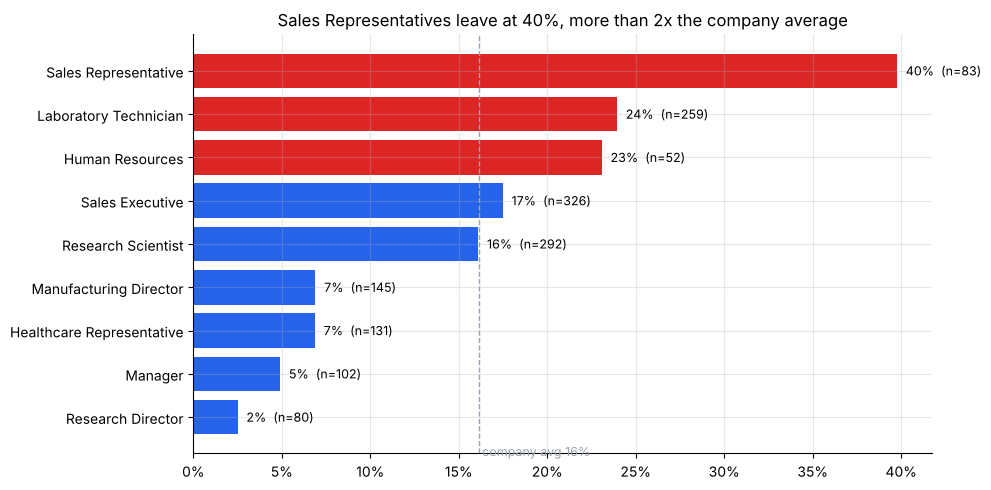

In [5]:
role = rate_table("JobRole").sort_values("attrition_rate")
fig, ax = plt.subplots(figsize=(10, 5))
colors = [RED if r > 0.2 else BLUE for r in role.attrition_rate]
ax.barh(role.index, role.attrition_rate, color=colors)
ax.axvline(overall, color=GREY, ls="--", lw=1)
ax.text(overall, -0.9, f" company avg {overall:.0%}", color=GREY, fontsize=9)
for i, (r, n) in enumerate(zip(role.attrition_rate, role.employees)):
    ax.text(r + 0.005, i, f"{r:.0%}  (n={n})", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title("Sales Representatives leave at 40%, more than 2x the company average")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/01_attrition_by_role.png", dpi=150)

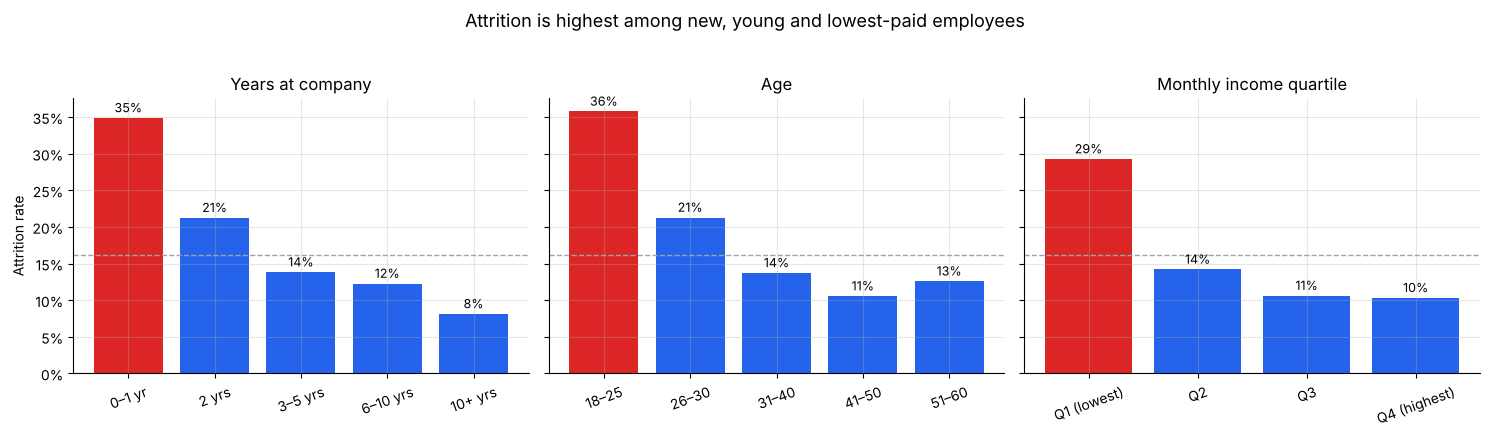

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, col, title in zip(axes, ["TenureBand", "AgeBand", "IncomeQuartile"],
                          ["Years at company", "Age", "Monthly income quartile"]):
    t = rate_table(col)
    bars = ax.bar(t.index.astype(str), t.attrition_rate, color=[RED if r > 0.25 else BLUE for r in t.attrition_rate])
    ax.bar_label(bars, labels=[f"{r:.0%}" for r in t.attrition_rate], padding=2, fontsize=9)
    ax.axhline(overall, color=GREY, ls="--", lw=1)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Attrition rate")
fig.suptitle("Attrition is highest among new, young and lowest-paid employees", y=1.03, fontsize=13)
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/02_attrition_by_tenure_age_income.png", dpi=150, bbox_inches="tight")

In [7]:
print(f"Median monthly income — leavers: ${hr.loc[hr.left == 1, 'MonthlyIncome'].median():,.0f}  "
      f"stayers: ${hr.loc[hr.left == 0, 'MonthlyIncome'].median():,.0f}")
u, p = stats.mannwhitneyu(hr.loc[hr.left == 1, "MonthlyIncome"], hr.loc[hr.left == 0, "MonthlyIncome"])
print(f"Mann-Whitney U test p-value: {p:.1e}")

Median monthly income — leavers: $3,202  stayers: $5,204
Mann-Whitney U test p-value: 3.0e-14


**Finding:** A third of first-year employees leave (35%), and so do 36% of employees aged 18–25 and 29% of the lowest-paid quartile. Leavers earn a median **$3,202/month vs $5,204** for those who stay. These groups overlap heavily: they are mostly entry-level (Job Level 1) staff.

## 3. Which factors can HR act on?
Demographics explain *who* leaves. For action, HR needs the **workplace levers** it controls. The chart compares each factor's highest-risk group with its lowest-risk group.

In [8]:
levers = {
    "OverTime": "Overtime",
    "BusinessTravel": "Business travel",
    "StockOptionLevel": "Stock option level",
    "EnvironmentSatisfaction_lbl": "Environment satisfaction",
    "JobSatisfaction_lbl": "Job satisfaction",
    "WorkLifeBalance_lbl": "Work-life balance",
    "JobInvolvement": "Job involvement",
    "MaritalStatus": "Marital status (context)",
}
rows = []
for col, name in levers.items():
    t = rate_table(col)
    hi, lo = t.attrition_rate.idxmax(), t.attrition_rate.idxmin()
    rows.append({"factor": name, "highest_risk_group": str(hi), "highest_rate": t.attrition_rate.max(),
                 "lowest_risk_group": str(lo), "lowest_rate": t.attrition_rate.min(),
                 "ratio": t.attrition_rate.max() / t.attrition_rate.min(), "p_value": t["p_value (chi²)"].iloc[0]})
lever_df = pd.DataFrame(rows).sort_values("ratio", ascending=False)
lever_df.round(3)

,factor,highest_risk_group,highest_rate,lowest_risk_group,lowest_rate,ratio,p_value
6,Job involvement,1,0.337,4,0.090,3.737,0.000
2,Stock option level,0,0.244,2,0.076,3.213,0.000
1,Business travel,Travel_Frequently,0.249,Non-Travel,0.080,3.114,0.000
0,Overtime,Yes,0.305,No,0.104,2.925,0.000
7,Marital status (context),Single,0.255,Divorced,0.101,2.530,0.000
5,Work-life balance,1 Bad,0.312,3 Better,0.142,2.197,0.001
4,Job satisfaction,1 Low,0.228,4 Very high,0.113,2.016,0.001
3,Environment satisfaction,1 Low,0.254,4 Very high,0.135,1.885,0.000


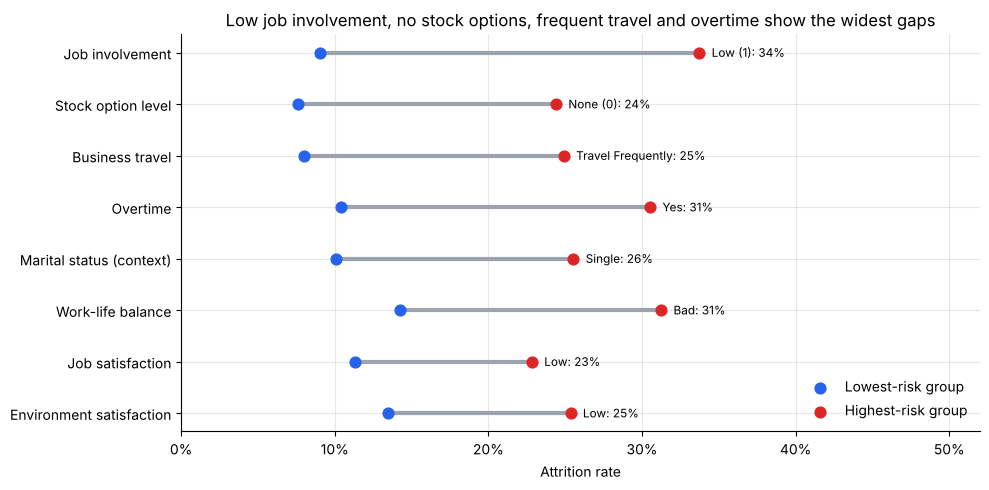

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
d = lever_df.sort_values("ratio")
y = np.arange(len(d))
ax.hlines(y, d.lowest_rate, d.highest_rate, color=GREY, lw=3)
ax.scatter(d.lowest_rate, y, color=BLUE, s=60, zorder=3, label="Lowest-risk group")
ax.scatter(d.highest_rate, y, color=RED, s=60, zorder=3, label="Highest-risk group")
for i, (_, r) in enumerate(d.iterrows()):
    grp = {"Job involvement": "Low (1)", "Stock option level": "None (0)"}.get(r.factor, r.highest_risk_group.replace("_", " ").lstrip("1 "))
    ax.text(r.highest_rate + 0.008, i, f"{grp}: {r.highest_rate:.0%}", va="center", fontsize=8.5)
ax.set_yticks(y, d.factor)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlim(0, 0.52)
ax.set_xlabel("Attrition rate")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Low job involvement, no stock options, frequent travel and overtime show the widest gaps")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/03_workplace_levers.png", dpi=150)

**Finding:** Employees working **overtime leave at 30.5% vs 10.4%** (2.9x). Low job involvement has the widest gap of all (34% vs 9%). Frequent travelers leave at 25% vs 8% for non-travelers, and employees with **no stock options** leave at 24% vs 8–9% at levels 1–2. Low environment satisfaction and "bad" work-life balance also roughly double the risk. All are significant (chi-square p < 0.01).

## 4. Risk model: logistic regression
A logistic regression shows each factor's effect **while holding the others constant**, which separates overtime's effect from, say, job level. It is explainable enough to share with HR.

In [10]:
features_num = ["Age", "MonthlyIncome", "YearsAtCompany", "YearsSinceLastPromotion", "DistanceFromHome",
                "NumCompaniesWorked", "TotalWorkingYears", "EnvironmentSatisfaction", "JobSatisfaction",
                "WorkLifeBalance", "JobInvolvement", "StockOptionLevel", "JobLevel", "TrainingTimesLastYear"]
features_cat = ["OverTime", "BusinessTravel", "MaritalStatus", "Department"]
X = pd.get_dummies(hr[features_num + features_cat], columns=features_cat, drop_first=True, dtype=float)
y = hr.left
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

# Scale only numeric features so yes/no flags keep a "category vs baseline" interpretation
def scale(train, other, cols=features_num):
    mu, sd = train[cols].mean(), train[cols].std()
    out = other.copy()
    out[cols] = (other[cols] - mu) / sd
    return out

model = LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5)
model.fit(scale(X_train, X_train), y_train)
test_prob = model.predict_proba(scale(X_train, X_test))[:, 1]

cv_scores = []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y):
    m = LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5)
    m.fit(scale(X.iloc[tr], X.iloc[tr]), y.iloc[tr])
    cv_scores.append(roc_auc_score(y.iloc[te], m.predict_proba(scale(X.iloc[tr], X.iloc[te]))[:, 1]))
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_prob):.3f}   |   5-fold CV AUC: {np.mean(cv_scores):.3f} ± {np.std(cv_scores):.3f}")
print(classification_report(y_test, (test_prob >= 0.5).astype(int), target_names=["Stayed", "Left"]))

Test ROC-AUC: 0.823   |   5-fold CV AUC: 0.818 ± 0.012
              precision    recall  f1-score   support

      Stayed       0.93      0.81      0.86       309
        Left       0.41      0.69      0.51        59

    accuracy                           0.79       368
   macro avg       0.67      0.75      0.69       368
weighted avg       0.85      0.79      0.81       368



An AUC of ~0.82 (stable across 5-fold cross-validation) means the model ranks a random leaver above a random stayer about 82% of the time. That is good enough to prioritize retention conversations, though not to make decisions about individuals on its own.

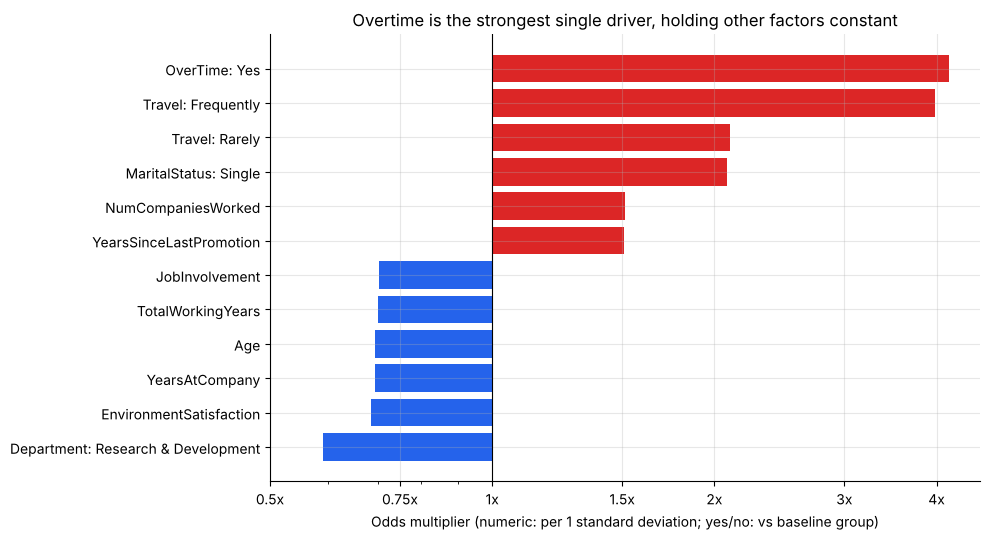

OverTime_Yes                        4.15
BusinessTravel_Travel_Frequently    3.98
BusinessTravel_Travel_Rarely        2.10
MaritalStatus_Single                2.08
NumCompaniesWorked                  1.51
YearsSinceLastPromotion             1.51
DistanceFromHome                    1.31
Department_Sales                    1.29
dtype: float64

In [11]:
coef = pd.Series(model.coef_[0], index=X.columns)
odds = np.exp(coef).sort_values()
top = pd.concat([odds.head(6), odds.tail(6)])
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top.index.str.replace("BusinessTravel_Travel_", "Travel: ").str.replace("_", ": "), top - 1, left=1,
        color=[BLUE if v < 1 else RED for v in top])
ax.axvline(1, color="black", lw=0.8)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3])
ax.get_xaxis().set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}x"))
ax.get_xaxis().set_minor_formatter(mtick.NullFormatter())
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 4])
ax.set_xlabel("Odds multiplier (numeric: per 1 standard deviation; yes/no: vs baseline group)")
ax.set_title("Overtime is the strongest single driver, holding other factors constant")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/04_model_drivers.png", dpi=150)
odds.sort_values(ascending=False).round(2).head(8)

**Reading the model:** Holding everything else constant, **overtime multiplies the odds of leaving by about 4.2x**, the largest effect. Frequent travel (4.0x vs non-travelers), being single (2.1x vs divorced), more previous employers and a longer gap since the last promotion (1.5x per standard deviation) also push risk up. Stock options, job satisfaction, environment satisfaction, job involvement and total experience pull it down.

## 5. Flag employees for retention conversations

In [12]:
hr["risk_score"] = model.predict_proba(scale(X_train, X))[:, 1]
hr["risk_tier"] = pd.cut(hr.risk_score, [0, 0.3, 0.6, 1.0], labels=["Low", "Medium", "High"])
tier = hr.groupby("risk_tier", observed=True).agg(employees=("left", "size"), actual_attrition=("left", "mean"))
tier["share_of_all_leavers"] = hr.groupby("risk_tier", observed=True).left.sum() / hr.left.sum()
tier.round(3)

,employees,actual_attrition,share_of_all_leavers
risk_tier,,,
Low,666,0.042,0.118
Medium,478,0.100,0.203
High,326,0.494,0.679


The **High** tier is 22% of employees (326) but holds **68% of all leavers**, and half of them (49%) left. HR can focus stay-interviews, compensation reviews and overtime checks there instead of spreading effort across all 1,470 employees. *(In production the model would be retrained regularly and scored on current employees only.)*

## 6. What does attrition cost?
**Assumption (adjustable):** replacing an employee costs **50% of annual salary** (recruiting, onboarding, lost productivity). This is a common HR rule of thumb; published estimates range from about 30% to over 100% depending on role level.

In [13]:
REPLACEMENT_COST_PCT = 0.50
leavers = hr[hr.left == 1]
annual_cost = (leavers.MonthlyIncome * 12 * REPLACEMENT_COST_PCT).sum()
ot_leavers = leavers[leavers.OverTime == "Yes"]
# If overtime staff left at the non-overtime rate, how many fewer leavers?
ot_staff = (hr.OverTime == "Yes").sum()
excess_ot_leavers = len(ot_leavers) - ot_staff * hr.loc[hr.OverTime == "No", "left"].mean()
avg_cost = (leavers.MonthlyIncome * 12 * REPLACEMENT_COST_PCT).mean()
print(f"Leavers: {len(leavers)}  |  estimated replacement cost: ${annual_cost:,.0f}")
print(f"Average cost per leaver: ${avg_cost:,.0f}")
print(f"Overtime-related excess leavers: {excess_ot_leavers:.0f} → ~${excess_ot_leavers * avg_cost:,.0f} at average cost")
print(f"A 20% reduction in attrition would save ~${0.2 * annual_cost:,.0f}")

Leavers: 237  |  estimated replacement cost: $6,807,246
Average cost per leaver: $28,723
Overtime-related excess leavers: 84 → ~$2,400,759 at average cost
A 20% reduction in attrition would save ~$1,361,449


## 7. Save results

In [14]:
summary_tables = {"attrition_by_role": rate_table("JobRole"), "attrition_by_tenure": rate_table("TenureBand"),
                  "attrition_by_income": rate_table("IncomeQuartile"), "attrition_by_overtime": rate_table("OverTime")}
for name, t in summary_tables.items():
    t.round(4).to_csv(f"{RESULTS_DIR}/{name}.csv")
lever_df.round(4).to_csv(f"{RESULTS_DIR}/workplace_levers.csv", index=False)
odds.sort_values(ascending=False).round(3).rename("odds_multiplier").to_csv(f"{RESULTS_DIR}/model_odds_ratios.csv")
tier.round(4).to_csv(f"{RESULTS_DIR}/risk_tiers.csv")
hr[["EmployeeNumber", "Department", "JobRole", "OverTime", "risk_score", "risk_tier", "Attrition"]] \
    .sort_values("risk_score", ascending=False).round(3).to_csv(f"{RESULTS_DIR}/employee_risk_scores.csv", index=False)
print("Saved result tables to results/")

Saved result tables to results/


## Recommendations

| # | Action | Evidence |
|---|---|---|
| 1 | **Audit and cap overtime**, starting with Sales Reps and Lab Technicians; add staff or rotate overtime | 30.5% vs 10.4% attrition; ~4.2x odds in the model |
| 2 | **Strengthen first-year onboarding and 90-day check-ins** | 35% of first-year employees leave |
| 3 | **Extend stock options (level 1+) to entry-level staff** | 24% attrition with no options vs 8–9% at levels 1–2 |
| 4 | **Review Sales Representative pay and career path** | 40% attrition; lowest income band leaves at 29% |
| 5 | **Limit frequent travel or add travel compensation** | 25% vs 8% for non-travelers |
| 6 | **Use the risk tiers for quarterly stay-interviews** | High tier = 22% of staff but 68% of leavers |

**Limitations:** The dataset is fictional and covers a single point in time (no exit dates), so the results show associations, not causes. The cost estimate depends on the replacement-cost assumption.